# What the fly sees: `flybrain.eyes`

`flybrain/eyes.py` has two ways to put a visual scene into the connectome:

1. **`Eyes`**: renders a scene of dark `Blob`s on a bright background onto the brain's 6,006
   photoreceptors (R1-6, R7, R8). Each photoreceptor has an azimuth from -1 (far left) to +1 (far
   right). The drive is luminance plus how much the luminance just changed. You pass it to
   `brain.step(eye_drive=...)`.
2. **`FeatureDetectors`**: skips the eye and the optic lobe. It drives four of the fly's own
   visual projection neuron types directly (LPLC2 for looming, LC4 for fast looming/threat,
   LPLC1 for small approaching objects, LC10a for a target to chase) on the side where the object
   is. SSH Fighter uses this route.

This notebook shows three stimuli through both routes: a **looming dark disc**, a **small moving
target**, and a **target on the left vs the right**. It then asks which superclasses and cell types
respond, on which side, and when.

**Before running:** `pip install flybrain matplotlib`. The first `FlyBrain()` downloads the brain
(~260 MB) once. Everything runs on the CPU (about 2 minutes). With an NVIDIA GPU you can switch to
`device="auto"`; individual spikes then differ from the saved outputs, but the statistics should match.

In [1]:
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent))  # lets a repository clone find flybrain without installing it
import flybrain
from flybrain import Blob, Eyes, FeatureDetectors, FlyBrain

brain = FlyBrain(device="cpu", seed=0)
print(f"flybrain {flybrain.__version__}: {brain.n:,} neurons on {brain.device}, step = {brain.dt * 1000:.0f} ms")

flybrain 0.1.0: 166,700 neurons on cpu, step = 20 ms


## The eyes in the model

The photoreceptors are found by cell type. Their azimuth was estimated from the MaleCNS optic
column tables (`flybrain build`): a column's front-to-back position becomes an azimuth, and the
left eye gets negative values. Elevation is dropped, so the "retina" is one-dimensional.

photoreceptor types: {'R1-6': 3377, 'R7': 1300, 'R8': 1329}
per eye: {'L': 2345, 'R': 3661}


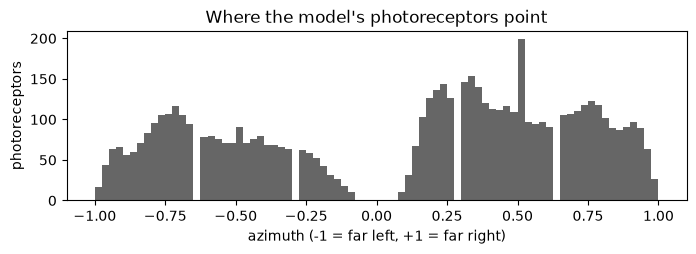

In [2]:
az = brain.azimuth
eye_side = np.where(az < 0, "L", "R")
types, counts = np.unique(brain.cell_type[brain.visual], return_counts=True)
print("photoreceptor types:", dict(zip(types.tolist(), counts.tolist())))
print("per eye:", {s: int((eye_side == s).sum()) for s in "LR"})

fig, ax = plt.subplots(figsize=(8, 2.2))
ax.hist(az, bins=80, color="0.4")
ax.set_xlabel("azimuth (-1 = far left, +1 = far right)")
ax.set_ylabel("photoreceptors")
ax.set_title("Where the model's photoreceptors point")
plt.show()

The two eyes are not the same size in the model. Fewer photoreceptors are assigned to the left
eye than to the right. This comes from the dataset as built, not from biology. Keep it in mind
when comparing sides below.

## Three stimuli

Each trial lasts 2 s (100 steps of 20 ms). The stimulus is on from 0.5 to 1.5 s, against a
uniform bright background. Each stimulus is a function of the step number that returns a list of
blobs:

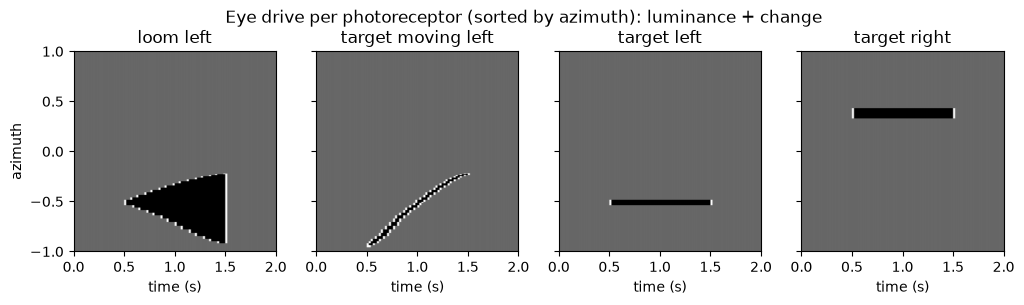

In [3]:
T, ON = 100, (25, 75)            # steps; stimulus on during steps 25..74
SEEDS = [0, 1, 2, 3, 4]


def phase(t):
    return (t - ON[0]) / (ON[1] - ON[0])          # 0 -> 1 while the stimulus is on


STIMULI = {
    # a dark disc on the left that grows from 2% to 40% of the half-field: something approaching
    "loom left": lambda t: [Blob(center=-0.5, half_width=0.02 + 0.38 * phase(t), darkness=1.0)],
    # a small dark target crossing the left eye from back to front
    "target moving left": lambda t: [Blob(center=-0.9 + 0.8 * phase(t), half_width=0.03, darkness=1.0)],
    # the same small target, still, on one side
    "target left": lambda t: [Blob(center=-0.5, half_width=0.03, darkness=1.0)],
    "target right": lambda t: [Blob(center=+0.5, half_width=0.03, darkness=1.0)],
}

order = np.argsort(az)
fig, axes = plt.subplots(1, len(STIMULI), figsize=(12, 2.6), sharey=True)
for ax, (name, blobs) in zip(axes, STIMULI.items()):
    eyes = Eyes(az)
    img = np.stack([eyes.drive(blobs(t) if ON[0] <= t < ON[1] else [])[order] for t in range(T)])
    ax.imshow(img.T, aspect="auto", cmap="gray", vmin=0, vmax=1, origin="lower",
              extent=[0, T * brain.dt, -1, 1])
    ax.set_title(name)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("azimuth")
fig.suptitle("Eye drive per photoreceptor (sorted by azimuth): luminance + change", y=1.04)
plt.show()

The drive is `clip(0.45 * luminance + 1.6 * |change|, 0, 1)`. A still dark target lowers the drive
where it sits. A moving or growing one adds a bright flash of "change" at its edges. Both ON and OFF
changes give the same positive flash, because the model has no separate ON and OFF channels at the input.

## Measuring a response

The network is never silent. Background noise makes neurons fire everywhere. So for every seed
we run the trial twice, with the same noise: once with the stimulus, and once with the blank
background. The **response** of a group of neurons is the extra spikes in the stimulus run.

Matched noise does not make the two runs identical. One extra spike changes everything
downstream of it, so the runs drift apart even in neurons the stimulus never reaches. To tell a
real response from that drift, we repeat over 5 seeds and report the mean with its standard error.
A response counts as **reliable** when the mean is more than 3 standard errors from zero and
has the same sign in every seed.

That test alone still lets drift through, because there are thousands of cell types. So we also
run a **sham**: the blank background plus one kick to a single random central-brain neuron at
stimulus onset, and nothing else. Whatever passes the test in the sham is drift. That count is
the floor to compare every stimulus against.

In [4]:
superclasses = np.unique(brain.superclass)
sides = np.array(["L", "R", "?"])
side_code = np.select([brain.side == "L", brain.side == "R"], [0, 1], 2)
group_of = np.searchsorted(superclasses, brain.superclass) * 3 + side_code     # superclass x side
BIN = 5                                                                       # 100 ms bins


def trial(seed, drive=lambda t: {}):
    """One 2 s run. Returns (spikes per superclass x side per 100 ms bin, spikes per neuron while on)."""
    brain.reset(seed)
    series = np.zeros((T // BIN, len(superclasses) * 3), np.int32)
    on_counts = np.zeros(brain.n, np.int32)
    for t in range(T):
        fired = brain.step(**drive(t))
        series[t // BIN] += np.bincount(group_of[fired], minlength=series.shape[1])
        if ON[0] <= t < ON[1]:
            on_counts[fired] += 1
    return series, on_counts


def eye_drive(blobs):
    eyes = Eyes(az)
    return lambda t: {"eye_drive": eyes.drive(blobs(t) if ON[0] <= t < ON[1] else [])}


def responses(make_drive, baseline_drive):
    """Stimulus minus matched baseline, per seed: (series, per-neuron counts)."""
    out_s, out_n = [], []
    for seed in SEEDS:
        s0, n0 = trial(seed, baseline_drive())
        s1, n1 = trial(seed, make_drive())
        out_s.append(s1 - s0)
        out_n.append(n1 - n0)
    return np.array(out_s), np.array(out_n)


def sham(base):
    """`base` drive plus one +1.5 V kick to a single random central-brain neuron at stimulus onset."""
    kick = int(np.random.default_rng(99).choice(np.flatnonzero(brain.superclass == "cb_intrinsic")))
    def make():
        drive = base()
        return lambda t: {**drive(t), **({"inject": [([kick], 1.5)]} if t == ON[0] else {})}
    return make


blank = lambda: eye_drive(lambda t: [])
eye_results = {name: responses(lambda b=blobs: eye_drive(b), blank) for name, blobs in STIMULI.items()}
eye_results["sham (one kick)"] = responses(sham(blank), blank)
print("done:", list(eye_results))

done: ['loom left', 'target moving left', 'target left', 'target right', 'sham (one kick)']


## Route 1: `Eyes` -> photoreceptors -> optic lobe

Extra spikes per 100 ms in each superclass and side over time (mean of 5 seeds, shading = 1 SE).
The grey band is when the stimulus is on.

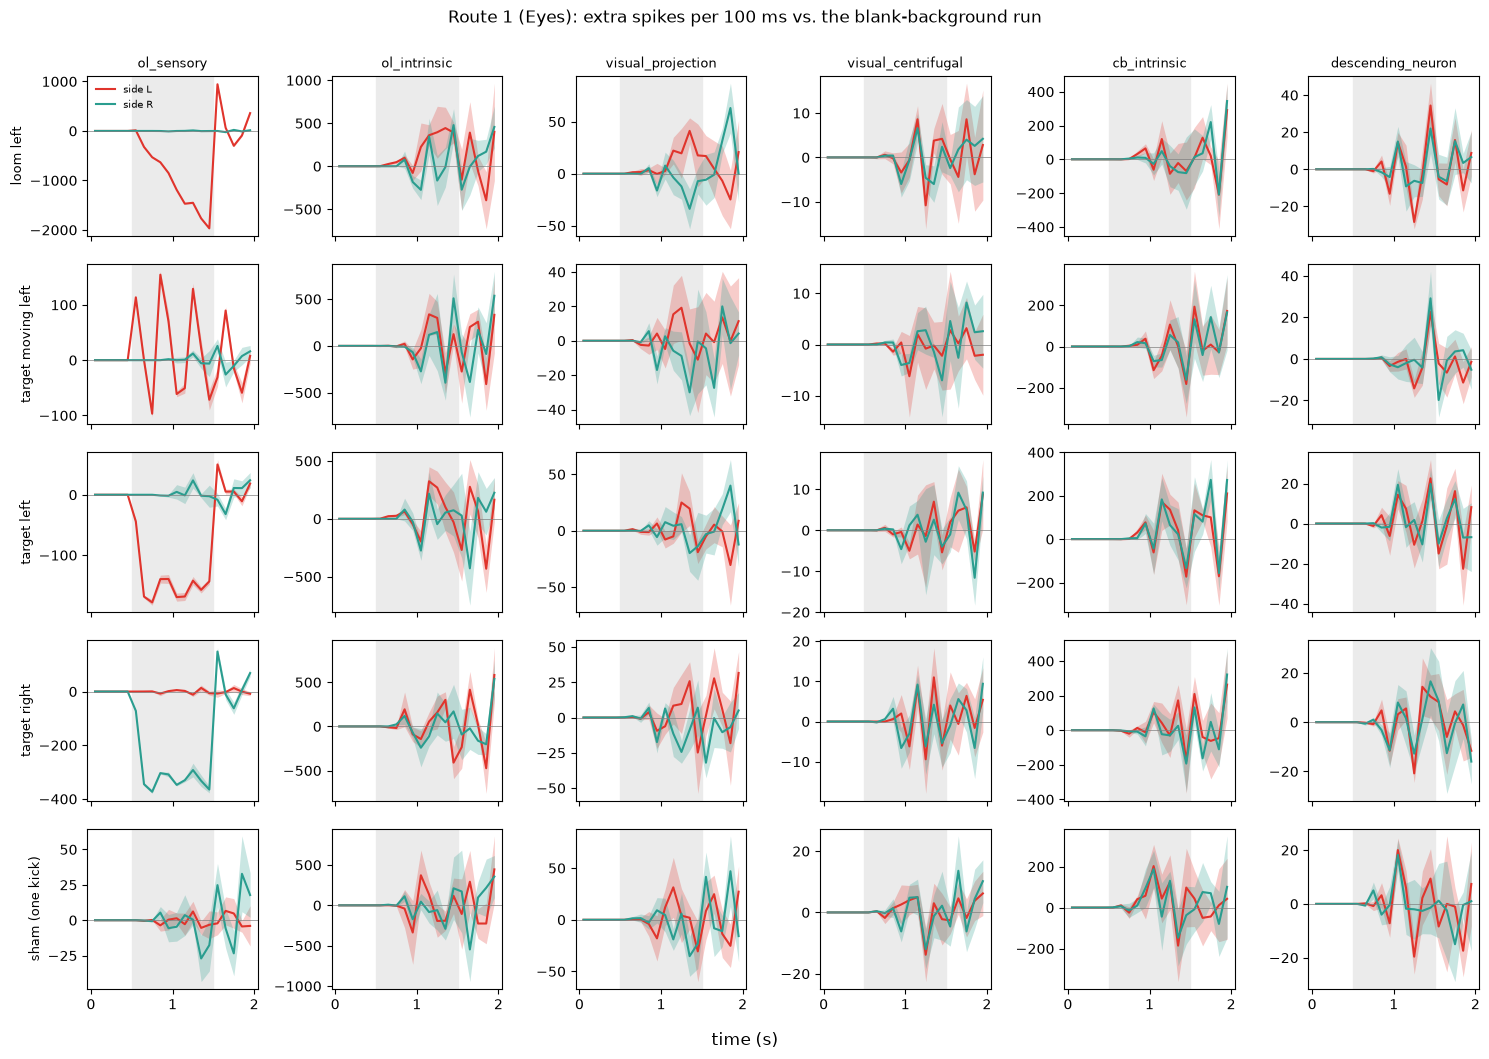

In [5]:
SHOW = ["ol_sensory", "ol_intrinsic", "visual_projection", "visual_centrifugal", "cb_intrinsic",
        "descending_neuron"]
colors = {"L": "#e0342c", "R": "#2a9d8f"}
tbin = (np.arange(T // BIN) + 0.5) * BIN * brain.dt


def plot_series(results, title):
    fig, axes = plt.subplots(len(results), len(SHOW), figsize=(15, 2.1 * len(results)), sharex=True)
    for row, (name, (series, _)) in enumerate(results.items()):
        for col, sc in enumerate(SHOW):
            ax = axes[row, col]
            k = int(np.searchsorted(superclasses, sc)) * 3
            for s in (0, 1):
                y = series[:, :, k + s]
                m, se = y.mean(0), y.std(0, ddof=1) / np.sqrt(len(y))
                ax.plot(tbin, m, color=colors[sides[s]], label=f"side {sides[s]}")
                ax.fill_between(tbin, m - se, m + se, color=colors[sides[s]], alpha=0.25, lw=0)
            ax.axvspan(ON[0] * brain.dt, ON[1] * brain.dt, color="0.92", zorder=0)
            ax.axhline(0, color="0.5", lw=0.5)
            if row == 0:
                ax.set_title(sc, fontsize=9)
            if col == 0:
                ax.set_ylabel(name, fontsize=9)
    axes[0, 0].legend(fontsize=7, frameon=False)
    fig.suptitle(title, y=1.0)
    fig.supxlabel("time (s)")
    fig.tight_layout()
    plt.show()


plot_series(eye_results, "Route 1 (Eyes): extra spikes per 100 ms vs. the blank-background run")

Which cell types respond reliably? For each stimulus, the table first gives how many type/side
groups pass the reliability test (compare with the sham). It then lists the reliable groups with
the largest total change in spikes while the stimulus was on, with the mean change per neuron of
that type over the 1 s.

In [6]:
type_side = np.char.add(np.char.add(brain.cell_type.astype(str), " "), brain.side.astype(str))
ts_names, ts_index = np.unique(type_side, return_inverse=True)
ts_sizes = np.bincount(ts_index)
ts_super = np.empty(len(ts_names), dtype=object)
ts_super[ts_index] = brain.superclass


def type_table(neuron_diffs, top=12, z=3.0):
    """Per type x side: mean change per neuron (over seeds), its SE, and whether it is reliable
    (|mean| > z SE and the same sign in every seed). Rows sorted by total change (mean x neurons)."""
    per_seed = np.array([np.bincount(ts_index, weights=d, minlength=len(ts_names)) for d in neuron_diffs]) / ts_sizes
    m, se = per_seed.mean(0), per_seed.std(0, ddof=1) / np.sqrt(len(per_seed))
    same_sign = (np.sign(per_seed) == np.sign(m)).all(0) & (m != 0)
    reliable = same_sign & (np.abs(m) > z * np.maximum(se, 1e-9))
    idx = np.flatnonzero(reliable)
    idx = idx[np.argsort(-np.abs(m[idx] * ts_sizes[idx]))][:top]
    rows = [(ts_names[i], ts_super[i], int(ts_sizes[i]), m[i], se[i]) for i in idx]
    return rows, int(reliable.sum()), int((reliable & (ts_sizes >= 5)).sum())


def print_tables(results):
    for name, (_, neuron_diffs) in results.items():
        rows, n_rel, n_big = type_table(neuron_diffs)
        print(f"\n{name}: {n_rel} type/side groups change reliably ({n_big} of them with 5+ neurons); largest totals:")
        print(f"  {'type side':16s} {'superclass':20s} {'neurons':>7s} {'total':>8s} {'per neuron':>15s}")
        for t, sc, size, m, se in rows:
            print(f"  {t:16s} {sc:20s} {size:7d} {m * size:+8.0f} {m:+8.2f} ± {se:.2f}")


print_tables(eye_results)


loom left: 88 type/side groups change reliably (62 of them with 5+ neurons); largest totals:
  type side        superclass           neurons    total      per neuron
  R1-6 L           ol_sensory              1112    -5620    -5.05 ± 0.02
  R8 L             ol_sensory               625    -3371    -5.39 ± 0.02
  R7 L             ol_sensory               608    -1178    -1.94 ± 0.01
  Mi4 L            ol_intrinsic             883     +154    +0.17 ± 0.01
  C2 L             ol_intrinsic             871     +103    +0.12 ± 0.02
  L1 L             ol_intrinsic             884     +102    +0.11 ± 0.01
  Tm20 L           ol_intrinsic             886      +93    +0.10 ± 0.01
  Tm5c L           ol_intrinsic             376      +89    +0.24 ± 0.04
  Mi9 L            ol_intrinsic             886      +78    +0.09 ± 0.01
  T5b L            ol_intrinsic             863      +68    +0.08 ± 0.02
  L3 L             ol_intrinsic             880      +55    +0.06 ± 0.01
  yDm8 L           ol_intrinsi

Left vs right: spikes added in each side's optic lobe (photoreceptors excluded) for the target on the left
and on the right. Mean over seeds ± SE.

target left   L optic lobe:     +552 ± 358 spikes
target left   R optic lobe:      +60 ± 215 spikes
target right  L optic lobe:      +47 ± 213 spikes
target right  R optic lobe:      +39 ± 451 spikes


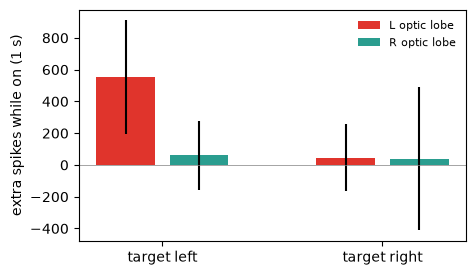

In [7]:
def side_totals(neuron_diffs, mask):
    return {s: np.array([d[mask & (brain.side == s)].sum() for d in neuron_diffs]) for s in "LR"}


optic = np.isin(brain.superclass, ["ol_intrinsic", "visual_projection", "visual_centrifugal"])
fig, ax = plt.subplots(figsize=(5, 3))
for k, name in enumerate(["target left", "target right"]):
    tot = side_totals(eye_results[name][1], optic)
    for j, s in enumerate("LR"):
        v = tot[s]
        ax.bar(k * 3 + j, v.mean(), yerr=v.std(ddof=1) / np.sqrt(len(v)), color=colors[s],
               label=f"{s} optic lobe" if k == 0 else None)
        print(f"{name:13s} {s} optic lobe: {v.mean():+8.0f} ± {v.std(ddof=1) / np.sqrt(len(v)):.0f} spikes")
ax.set_xticks([0.5, 3.5], ["target left", "target right"])
ax.axhline(0, color="0.5", lw=0.5)
ax.set_ylabel("extra spikes while on (1 s)")
ax.legend(frameon=False, fontsize=8)
plt.show()

## Route 2: `FeatureDetectors` -> visual projection neurons

`FeatureDetectors.inject(opp=(dx, size), threat=...)` takes an object `dx` screen units to the
side of the fly, with apparent `size`. It turns the object's angle, and how fast that angle grows,
into voltage on LPLC2/LC4/LPLC1/LC10a on that side. We give it the same three kinds of stimulus:
an object approaching on the left (its size grows), a small target moving across the left side,
and a small target held on the left or the right. The baseline is the same seed with nothing
injected.

neurons per detector channel: {'loom L': 94, 'loom R': 91, 'threat L': 71, 'threat R': 55, 'shot L': 68, 'shot R': 66, 'chase L': 135, 'chase R': 140}

peak voltage each channel gets per step:
  loom left            {'loomL': 0.3, 'chaseL': 0.8}
  target moving left   {'loomL': 0.1, 'chaseL': 0.63}


  target left          {'chaseL': 0.61}
  target right         {'chaseR': 0.61}


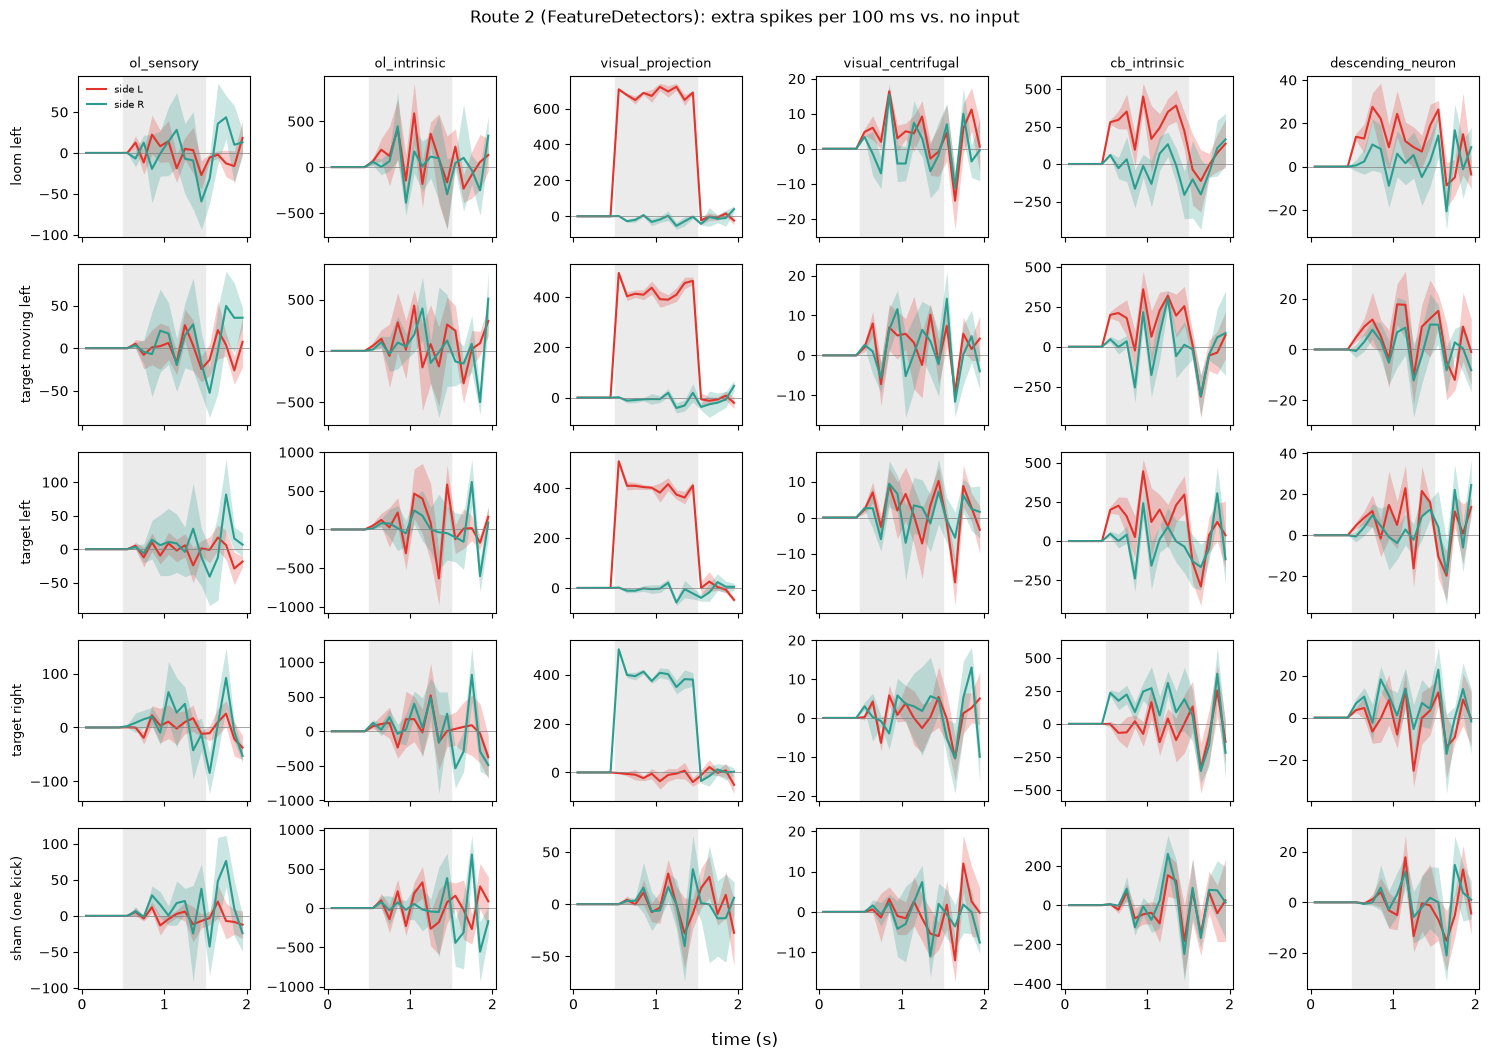


loom left: 1117 type/side groups change reliably (227 of them with 5+ neurons); largest totals:
  type side        superclass           neurons    total      per neuron
  LC10a L          visual_projection        135    +3906   +28.94 ± 0.37
  LPLC2 L          visual_projection         94    +2240   +23.83 ± 0.05
  C3 L             ol_intrinsic             887     +323    +0.36 ± 0.07
  LC10d L          visual_projection        108     +302    +2.80 ± 0.05
  PFNp L           cb_intrinsic             144     -232    -1.61 ± 0.36
  AOTU008 L        cb_intrinsic              12     +230   +19.18 ± 0.18
  LT52 L           visual_projection         17     +202   +11.87 ± 0.18
  PFNp R           cb_intrinsic             146     -179    -1.23 ± 0.33
  Mi13 L           ol_intrinsic             457     -152    -0.33 ± 0.10
  CB0007,CB0739 L  cb_intrinsic               6     +146   +24.37 ± 0.37
  Lawf2 L          ol_intrinsic             195     +138    +0.71 ± 0.07
  C2 L             ol_intri

In [8]:
OBJECTS = {   # (dx, size) of the object at step t, while the stimulus is on
    "loom left": lambda t: (-40.0, 4.0 + 60.0 * phase(t)),            # approaching: size grows
    "target moving left": lambda t: (-100.0 + 80.0 * phase(t), 3.0),  # small, crossing the left side
    "target left": lambda t: (-50.0, 3.0),
    "target right": lambda t: (+50.0, 3.0),
}


def detector_drive(opp_at, record=None):
    fd = FeatureDetectors(brain)
    def drive(t):
        if not ON[0] <= t < ON[1]:
            fd.inject(opp=None)
            return {}
        inject = fd.inject(opp=opp_at(t))
        if record is not None:
            for ch, v in fd.last.items():
                record[ch] = max(record[ch], v)
        return {"inject": inject}
    return drive


fd = FeatureDetectors(brain)
print("neurons per detector channel:", {f"{ch} {s}": len(fd.cells[ch][s]) for ch in fd.cells for s in "LR"})
print("\npeak voltage each channel gets per step:")
for name, opp_at in OBJECTS.items():
    peak = defaultdict(float)
    drive = detector_drive(opp_at, peak)
    for t in range(T):
        drive(t)
    print(f"  {name:20s}", {ch: round(v, 2) for ch, v in peak.items() if v > 0})

nothing = lambda: (lambda t: {})
detector_results = {name: responses(lambda o=opp_at: detector_drive(o), nothing) for name, opp_at in OBJECTS.items()}
detector_results["sham (one kick)"] = responses(sham(nothing), nothing)
plot_series(detector_results, "Route 2 (FeatureDetectors): extra spikes per 100 ms vs. no input")
print_tables(detector_results)

What reaches the brain's outputs? Extra spikes in a few identified descending neurons while the
stimulus is on, per side, for both routes. DNp01 is the giant fiber (escape). DNa02 steers.
DNp02, DNp04 and DNp11 are other looming-sensitive descending neurons.

In [9]:
DNS = ["DNp01", "DNp02", "DNp04", "DNp11", "DNa02"]
print(f"{'':26s}" + "".join(f"{d + ' ' + s:>12s}" for d in DNS for s in "LR"))
for route, results in [("Eyes", eye_results), ("FeatureDetectors", detector_results)]:
    for name, (_, neuron_diffs) in results.items():
        cells = []
        for d in DNS:
            for s in "LR":
                idx = brain.cells([d], side=s)
                v = np.array([nd[idx].sum() for nd in neuron_diffs])
                cells.append(f"{v.mean():+7.1f}±{v.std(ddof=1) / np.sqrt(len(v)):<4.1f}")
        print(f"{route[:5]:5s} {name:20s}" + "".join(f"{c:>12s}" for c in cells))

                               DNp01 L     DNp01 R     DNp02 L     DNp02 R     DNp04 L     DNp04 R     DNp11 L     DNp11 R     DNa02 L     DNa02 R
Eyes  loom left              +0.0±0.0    +0.0±0.0    +0.2±0.2    +0.0±0.0    +0.2±0.2    +0.2±0.2    +0.0±0.0    +0.0±0.0    -0.2±0.2    +0.0±0.0 


Eyes  target moving left     +0.0±0.0    +0.0±0.0    +0.0±0.0    +0.0±0.0    +0.2±0.2    +0.2±0.2    +0.0±0.0    +0.0±0.0    +0.0±0.0    +0.0±0.0 
Eyes  target left            +0.0±0.0    +0.0±0.0    +0.2±0.2    +0.0±0.0    +0.2±0.2    +0.0±0.0    +0.0±0.0    -0.2±0.2    +0.0±0.0    +0.0±0.0 


Eyes  target right           +0.0±0.0    +0.0±0.0    +0.0±0.0    +0.0±0.0    +0.2±0.2    +0.0±0.0    +0.0±0.0    -0.2±0.2    +0.0±0.0    +0.2±0.2 
Eyes  sham (one kick)        +0.0±0.0    +0.0±0.0    +0.2±0.2    +0.0±0.0    +0.2±0.2    +0.2±0.2    +0.0±0.0    +0.0±0.0    -0.2±0.2    +0.0±0.0 


Featu loom left              +9.8±0.2    -0.2±0.2    +0.0±0.0    +0.0±0.0   +12.0±0.0    +0.2±0.2    +0.4±0.2    -0.2±0.2    +4.2±0.2    -0.4±0.2 
Featu target moving left     +0.8±0.4    -0.2±0.2    -0.2±0.2    +0.0±0.0    +1.6±0.2    +0.2±0.2    +0.2±0.2    +0.0±0.0    +3.4±0.2    -0.4±0.2 


Featu target left            +0.0±0.0    -0.2±0.2    -0.2±0.2    +0.0±0.0    -0.2±0.2    +0.4±0.2    +0.2±0.2    -0.2±0.2    +3.4±0.2    -0.4±0.2 
Featu target right           +0.0±0.0    -0.2±0.2    -0.2±0.2    +0.0±0.0    -0.2±0.2    +0.2±0.2    +0.0±0.0    +0.8±0.2    +0.0±0.0    +3.0±0.3 


Featu sham (one kick)        +0.0±0.0    -0.2±0.2    +0.0±0.0    +0.0±0.0    -0.2±0.2    +0.2±0.2    +0.0±0.0    +0.0±0.0    +0.2±0.2    -0.4±0.2 


## What we found

Numbers are from the saved CPU run: 5 seeds, stimulus on for 1 s. They may shift slightly on a
machine with a different thread count.

**Route 1, `Eyes`: the signal reaches the optic lobe but stops there.**
* The looming disc darkens the left eye, and left photoreceptors fire about 10,000 fewer spikes
  (R1-6, R7, R8; about -5 spikes per neuron).
* Because photoreceptors are histaminergic (inhibitory in the model), the left lamina and medulla
  fire a little *more*: Mi4, C2, L1, Tm20, Tm5c, Mi9, T5b, L3 (+50 to +150 spikes per type, +0.1
  to +0.2 per neuron). That is an OFF-like response produced by the wiring and transmitter signs,
  and it is ipsilateral. It is small: these changes are larger than any change in the sham (largest
  41 spikes), but they amount to a fraction of a spike per neuron.
* The number of type/side groups that pass the reliability test is close to the sham's: 88 for
  the loom, 41-56 for the targets, 80 for the sham. Apart from the photoreceptors and the
  early optic lobe neurons above, the eye route's downstream "responses" cannot be told apart
  from drift.
* The small targets (3% of the half-field) only move their own photoreceptors. The left-vs-right
  optic lobe totals are within their error bars (e.g. +552 ± 358 vs +60 ± 215 spikes).
* No descending neuron in the table responds to any eye stimulus beyond ±0.2 spikes, the same as
  the sham. Through this route, the brain's outputs do not register looming or a target.

**Route 2, `FeatureDetectors`: strong, side-specific responses all the way to descending neurons.**
* The driven types fire hard on the stimulated side: LC10a (+26 to +29 spikes per neuron) for
  every stimulus, LPLC2 (+24) for the loom.
* Downstream of them, the connectome recruits the same-side anterior optic tubercle and its
  partners: AOTU008 (+18 to +19 per neuron), LT52 (+11), LC10d (+2), CB0007/CB0739, CB3127,
  CB4184. Some of these are themselves visual projection neurons (LC10d, LT52) that the detector
  never drove directly. PFNp in the central complex fires *less* (-1.2 to -1.6 per neuron).
* Descending neurons: the loom on the left drives DNp01 (giant fiber) L +9.8 and DNp04 L +12.0
  spikes, with the right sides unchanged. Every target drives the steering neuron DNa02 on its own
  side (+3.0 to +3.4) and not the other side. The sham changes no descending neuron by more than 0.4.
* So the escape and steering pathways are side-specific in the wiring, as the quickstart notebook
  found. But the visual selectivity in this route (looming vs target) is ours: we chose which
  neurons each stimulus drives.

**In short:** with this simple eye model, the optic lobe relays a weak, local OFF-like signal and
nothing behaviourally relevant reaches the outputs. To make the brain act on what it "sees",
flybrain currently skips the optic lobe with `FeatureDetectors`. A better photoreceptor/lamina
model (graded, ON/OFF-split, two-dimensional) is open work.

## What `eyes.py` simplifies

Read the results above with these limits in mind. The model is much simpler than a fly's eye:

* **One dimension.** The scene is a strip of azimuths. There is no elevation, so a disc and a
  vertical bar look the same. Each photoreceptor's azimuth is an estimate from the optic column
  tables (front-to-back position mapped linearly to -1..1). It is not a measured receptive field.
  Unplaced photoreceptors get a mid-eye guess.
* **No optics or photoreceptor physiology.** No acceptance angles, no adaptation to brightness,
  no colour (R7/R8 get the same drive as R1-6), no polarisation.
* **One crude temporal filter.** The drive is luminance plus the absolute frame-to-frame change.
  Brightening and darkening give the same "change" signal, so ON and OFF are not separated at the
  input. Any ON/OFF difference downstream comes from the wiring and the transmitter signs.
* **Spikes where real flies use graded potentials.** Photoreceptors, lamina and many medulla
  neurons signal with graded voltage in real flies. Here they are leaky integrate-and-fire units
  at 20 ms steps, with the same tau, threshold, tonic drive and noise as every other neuron. The
  synapse signs come from predicted transmitters (histamine, GABA and glutamate are inhibitory).
  This is why `eyes.py` calls the eye route "kept for completeness": the signal weakens as it
  passes through the lamina.
* **`FeatureDetectors` is a shortcut, not vision.** It skips the whole optic lobe. Hand-set
  gains turn an object's angle and growth into voltage on four projection neuron types that we
  chose from the literature. The detectors' selectivity is assumed. Only what happens downstream of
  those neurons comes from the connectome.
* **One male fly, one connectome, untuned.** MaleCNS v1.0 weights, synapse counts normalised per
  neuron, with hand-calibrated tonic drive, gain and noise. None of the numbers here have been
  checked against recordings from real flies.